In [280]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer
import sklearn
import codecs
import os

In [281]:
DATA_ROOT = ""
TRAIN_DIR = os.path.join(DATA_ROOT, "TRAIN")
TEST_DIR = os.path.join(DATA_ROOT, "TEST")
print(sorted(os.listdir(TRAIN_DIR))) # should list class folders

['course', 'faculty', 'project', 'student']


In [282]:
docs = {}
for c in os.listdir(TRAIN_DIR):
    docs[c] = {}
    for uni in os.listdir(os.path.join(TRAIN_DIR, c)):
        for file in os.listdir(os.path.join(TRAIN_DIR, c, uni)):
            docs[c][file] = []
            with codecs.open(os.path.join(TRAIN_DIR, c, uni, file), "r", encoding='utf-8',errors='ignore') as f:
                text = f.read()
                words = text.lower().split()
                for word in words:
                    word.strip(".,!?()[]:;")
                    if word.isalpha() and len(word) > 1:
                        docs[c][file].append(word)

docs["course"]["dummy"] = ["course"]*1000
docs["project"]["dummy"] = ["project"]*1000
docs["faculty"]["dummy"] = ["professor", "faculty"]*1000
docs["student"]["dummy"] = ["student"]*1000

In [283]:
docs_test = {}
for file in os.listdir(TEST_DIR):
    docs_test[file] = []
    with codecs.open(os.path.join(TEST_DIR, file), "r", encoding='utf-8',errors='ignore') as f:
        text = f.read()
        words = text.lower().split()
        for word in words:
            word.strip(".,!?()[]:;")
            if word.isalpha() and len(word) > 1:
                docs_test[file].append(word)

In [284]:
with open("stopwords.txt", "r") as f:
    stopwords = set(f.read().split())
docs_stopwords = {}
for c in docs:
    docs_stopwords[c] = {}
    for f in docs[c]:
        docs_stopwords[c][f] = []
        for w in docs[c][f]:
            if w not in stopwords:
                docs_stopwords[c][f].append(w)

docs_test_stopwords = {}
for f in docs_test:
    docs_test_stopwords[f] = []
    for w in docs_test[f]:
        if w not in stopwords:
            docs_test_stopwords[f].append(w)

In [285]:
print(docs_stopwords["course"]["file_^^issl.cs.byu.edu^docs^CS556^Syllabus95.html"])

['document', 'created', 'rtf', 'source', 'rtftohtml', 'version', 'cs', 'interactive', 'software', 'systems', 'purpose', 'course', 'student', 'techniques', 'creating', 'graphical', 'user', 'course', 'cover', 'basic', 'concepts', 'windowing', 'interactive', 'user', 'interface', 'management', 'systems', 'basic', 'concepts', 'user', 'interface', 'design', 'course', 'structure', 'olsen', 'tmcb', 'mw', 'tmcb', 'request', 'order', 'post', 'question', 'instructor', 'appointment', 'interface', 'management', 'systems', 'packet', 'book', 'store', 'silicon', 'graphics', 'indys', 'running', 'user', 'interface', 'software', 'goal', 'graduate', 'education', 'actual', 'content', 'learn', 'learn', 'learn', 'things', 'course', 'consist', 'lecture', 'time', 'reading', 'problems', 'assigned', 'class', 'class', 'members', 'read', 'understood', 'material', 'students', 'asked', 'class', 'present', 'short', 'portions', 'class', 'participation', 'graded', 'discussed', 'formation', 'study', 'groups', 'prepare',

In [286]:
alpha = 1
total_docs_stopwords = 0
total_words_in_class_stopwords = {}
v_stopwords = set()
P_k_stopwords = {}
P_w_k_stopwords = {}

for c in docs_stopwords:
    total_docs_stopwords += len(docs_stopwords[c])
    total_words_in_class_stopwords[c] = 0
    P_w_k_stopwords[c] = {}

for c in docs_stopwords:
    P_k_stopwords[c] = len(docs_stopwords[c])/total_docs_stopwords
    for f in docs_stopwords[c]:
        total_words_in_class_stopwords[c] += len(docs_stopwords[c][f])

for c in docs_stopwords:
    seen_class = set()
    for f in docs_stopwords[c]:
        for w in set(docs_stopwords[c][f]):
            if w not in v_stopwords:
                v_stopwords.add(w)
            if w not in seen_class:
                seen_class.add(w)
                P_w_k_stopwords[c][w] = alpha
            P_w_k_stopwords[c][w] += docs_stopwords[c][f].count(w)

for c in P_w_k_stopwords:
    for w in P_w_k_stopwords[c]:
        P_w_k_stopwords[c][w] /= total_words_in_class_stopwords[c] + len(v_stopwords)*alpha

In [287]:
from collections import Counter

def predict_stopwords(words):
    P_k_t = {}
    n_t_w = Counter(words)
    
    for c in docs_stopwords:
        P_k_t[c] = np.log(P_k_stopwords[c])
        denom = total_words_in_class_stopwords[c] + len(v_stopwords) * alpha
        unseen_logprob = np.log(alpha / denom)
        
        for w, count in n_t_w.items():
            if w not in v_stopwords:
                continue
            if w in P_w_k_stopwords[c]:
                P_k_t[c] += np.log(P_w_k_stopwords[c][w]) * count
            else:
                P_k_t[c] += unseen_logprob * count

    return max(P_k_t, key=P_k_t.get)


labels = list(docs_stopwords.keys())

confMatrix_stopwords = np.zeros((20, 20))
for c in docs_stopwords:
    for f in docs_stopwords[c]:
        predicted = predict_stopwords(docs_stopwords[c][f])
        true = c
        confMatrix_stopwords[labels.index(predicted), labels.index(true)] += 1

# print(confMatrix_stopwords)

accuracy_stopwords = np.trace(confMatrix_stopwords)/np.sum(confMatrix_stopwords)
print(f"Accuracy: {accuracy_stopwords}")

Accuracy: 0.9155327342747112


In [288]:
X = []
y = []
X_test = []
for c in docs_stopwords:
    for f in docs_stopwords[c]:
        X.append(" ".join(docs_stopwords[c][f]))
        y.append(c)
print(X[:5])

for f in docs_test_stopwords:
    X_test.append(" ".join(docs_test_stopwords[f]))
print(X_test[:5])

['gmt gmt network protocols implementation office tuesday teaching office ta class texts background rfc draft multicast routing ip texas internet platform netsim mobility support address allocation draft http digest access individual turn sample solutions group project project group project configuration files group project read note yu feng add my pgp public key size wed sep cdt', 'gmt gmt background parallel languages compilers languages tuesday thursday ens taylor office tuesday thursday put announcements case tera computer assignment posix threads skeleton assignment communication communication mpi manual time spent shared memory assignment practical parallel programming partitioning dynamic adaptive grid december', 'gmt gmt html public html aix computer systems architecture fall herb mesquite class liu ta station yang ta station assignment ps file program program ps file program final classmates post message news page created august send email', 'gmt gmt techniques fall techniques

In [289]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [290]:
vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

modelNB = MultinomialNB()
modelNB.fit(X_train_vectorized, y_train)

MultinomialNB()

Accuracy: 83.33333333333334%


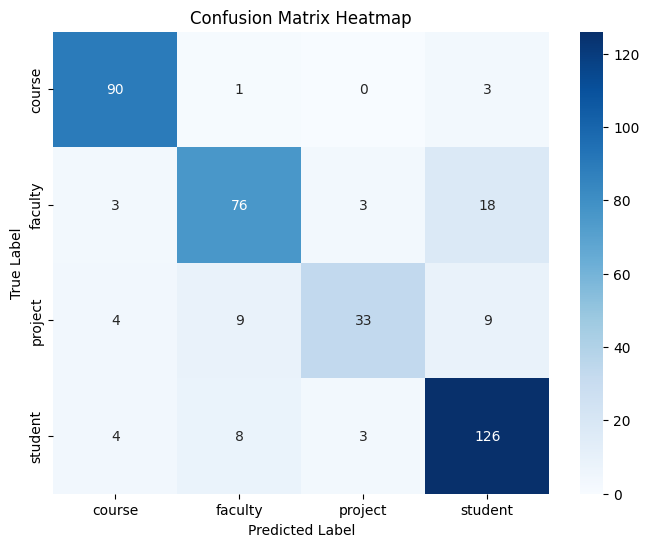

In [291]:
y_predNB = modelNB.predict(X_test_vectorized)
accuracyNB = accuracy_score(y_test, y_predNB)
conf_matrixNB = confusion_matrix(y_test, y_predNB)

print(f'Accuracy: {accuracyNB *100}%')

class_labels = np.unique(y_test)
plt.figure(figsize=(8, 6))

sns.heatmap(conf_matrixNB, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [292]:
from sklearn.svm import SVC

modelSVC = SVC(kernel="linear")
modelSVC.fit(X_train_vectorized, y_train)

SVC(kernel='linear')

Accuracy: 82.3076923076923%


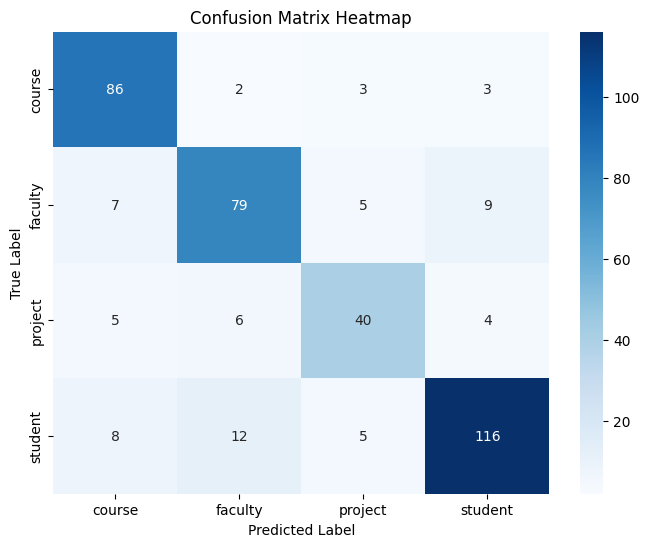

In [293]:
y_predSVC = modelSVC.predict(X_test_vectorized)
accuracySVC = accuracy_score(y_test, y_predSVC)
conf_matrixSVC = confusion_matrix(y_test, y_predSVC)

print(f'Accuracy: {accuracySVC *100}%')

class_labels = np.unique(y_test)
plt.figure(figsize=(8, 6))

sns.heatmap(conf_matrixSVC, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [294]:
with open("112401002.txt", "w") as file:
    pass

for f in docs_test_stopwords:
    predicted = predict_stopwords(docs_test_stopwords[f])
    with open("112401002.txt", "a") as file:
        file.write(f"{f} {predicted}\n")

I ended up going with Naive Bayes because the accuracy of Naive Bayes was slightly better than SVC in the above train test split data, and also because NB is good at text classification. Especially in such a case, where words like "course", "project", "student", "professor" etc give clues on which class it is in. I added dummy files in each class so that the words such as those above are given more weight in deciding the class.